[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%9C%8B%E6%87%82%E8%B3%87%E6%96%99%E8%88%87%E9%81%B8%E5%B0%8D%E5%9C%96%E8%A1%A8/README.ipynb)

# 看懂資料與選對圖表——再把圖表交給 AI

拿到一份陌生資料，最難的不是寫程式，而是**不知道該問什麼、該畫什麼**。本章教你一套固定流程：

1. **認識資料**：每一欄是類別、數值、時間，還是識別碼？
2. **問對問題**：主管的問題，幾乎都屬於「比較、組成、分布、關係、趨勢」五類之一。
3. **選對圖表**：問題類型決定圖表類型。
4. **交給 AI**：畫圖前，請 AI 建議問題；畫圖後，把圖交給 AI 解讀、診斷、改良。
5. **自己驗證**：AI 會看錯圖，數字一定要用 pandas 核對。

> 範例使用課程虛構的手搖飲品牌「茶語時光」模擬資料。

In [1]:
# 📦 準備資料：優先使用本章「學生素材」資料夾，沒有的話（例如在 Colab）自動下載本章素材壓縮檔
import os, shutil, zipfile, urllib.request

FILES = ['茶語時光_每日營收_2024.csv', '茶語時光_訂單抽樣_2024-07.csv']
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%9C%8B%E6%87%82%E8%B3%87%E6%96%99%E8%88%87%E9%81%B8%E5%B0%8D%E5%9C%96%E8%A1%A8/%E7%9C%8B%E6%87%82%E8%B3%87%E6%96%99%E8%88%87%E9%81%B8%E5%B0%8D%E5%9C%96%E8%A1%A8_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

for f in FILES:
    if not os.path.exists(f) and os.path.exists(os.path.join('學生素材', f)):
        shutil.copy(os.path.join('學生素材', f), f)
if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name
            if inner in FILES:
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())
print('✅ 資料準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 資料準備完成： ['茶語時光_每日營收_2024.csv', '茶語時光_訂單抽樣_2024-07.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援 ---
# 使用 mplfonts 自動套用思源黑體，避免圖表中文出現亂碼或方塊字
%pip install -q mplfonts

from mplfonts import use_font
use_font("Noto Sans CJK TC")

## 1. 認識資料：每一欄是什麼型態？

| 型態 | 例子 | 能做的事 |
| --- | --- | --- |
| 類別 | 門市、品項、付款方式 | 計數、分組比較 |
| 順序類別 | 甜度（無糖→正常糖）、滿意度 1～5 | 計數，而且**要照順序排** |
| 數值 | 金額、杯數、氣溫 | 加總、平均、看分布 |
| 時間 | 日期、訂單時間 | 看趨勢、週期 |
| 識別碼 | 訂單編號、會員編號 | **只能數有幾個，不能加總或平均** |

下面這個小工具會自動幫你判斷，以後遇到任何資料都能用：

In [3]:
# 🩺 資料健檢小工具：自動判斷每一欄的「型態」，並建議適合的分析與圖表（可以複製到任何專案使用）
import pandas as pd

def 認識資料(df):
    rows = []
    for col in df.columns:
        s = df[col]
        name = str(col).lower()
        n_unique = s.nunique(dropna=True)
        as_number = pd.to_numeric(s, errors='coerce')                     # 試著把整欄轉成數字
        number_like = as_number.notna().sum() >= 0.9 * max(s.notna().sum(), 1)
        if any(k in name for k in ['編號', '代碼', 'id', 'code']):
            kind, tip = '識別碼', '只能「數有幾個」，不要加總或平均'
        elif any(k in name for k in ['經度', '緯度', 'longitude', 'latitude', 'lat', 'lng']):
            kind, tip = '地理座標', '畫在地圖上，或用散佈圖看位置'
        elif pd.api.types.is_datetime64_any_dtype(s):
            kind, tip = '時間', '趨勢 → 折線圖（resample、rolling）'
        elif pd.api.types.is_numeric_dtype(s):
            if n_unique <= 7:
                kind, tip = '數值（只有少數幾種）', '可能是評分或等級 → 依順序排的長條圖'
            else:
                kind, tip = '數值', '分布 → 直方圖／盒鬚圖；關係 → 散佈圖；比較 → 分組加總後畫長條圖'
        elif number_like:
            kind, tip = '⚠️ 數字卻存成文字', '先用 pd.to_numeric(..., errors="coerce") 轉成數字'
        elif pd.to_datetime(s, errors='coerce', format='mixed').notna().mean() > 0.9:
            kind, tip = '時間（目前是文字）', '先用 pd.to_datetime 轉換，再看趨勢 → 折線圖'
        elif n_unique <= 30:
            kind, tip = '類別', '比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）'
        else:
            kind, tip = '文字／種類很多的類別', '先取前 10 名或分組，再畫圖'
        rows.append({'欄位': col, '判斷型態': kind, '缺值%': round(s.isnull().mean() * 100, 1),
                     '不重複數': n_unique, '範例': '、'.join(s.dropna().astype(str).unique()[:3]), '建議': tip})
    return pd.DataFrame(rows).set_index('欄位')


def 資料說明給AI(df, 資料名稱):
    """產生一段可以直接複製貼給 AI 的資料說明。"""
    report = 認識資料(df)[['判斷型態', '缺值%', '不重複數', '範例']]
    text = (f'【資料名稱】{資料名稱}\n【大小】{df.shape[0]} 列 × {df.shape[1]} 欄\n\n'
            f'【每一欄的型態】\n{report.to_string()}\n\n【前 5 列】\n{df.head().to_string()}\n')
    print(text)
    return text

In [4]:
daily = pd.read_csv('茶語時光_每日營收_2024.csv', parse_dates=['日期'])
orders = pd.read_csv('茶語時光_訂單抽樣_2024-07.csv', parse_dates=['訂單時間'])
認識資料(orders)

,判斷型態,缺值%,不重複數,範例,建議
欄位,,,,,
訂單編號,識別碼,0.0,4000,T240701000015、T240701000019、T240701000026,只能「數有幾個」，不要加總或平均
訂單時間,時間,0.0,3995,2024-07-01 17:32:29、2024-07-01 22:57:46、2024-0...,趨勢 → 折線圖（resample、rolling）
門市,類別,0.0,5,台北信義店、台北西門店、台中逢甲店,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
品項,類別,0.0,9,鮮奶綠、檸檬紅茶、冬瓜檸檬,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
類別,類別,0.0,5,鮮奶、果茶、奶茶,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
尺寸,類別,0.0,2,中、大,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
甜度,類別,0.0,5,半糖、少糖、微糖,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
冰塊,類別,0.0,5,正常冰、微冰、少冰,比較 → 排序長條圖；組成 → 百分比堆疊長條（5 類以內才用圓餅圖）
數量,數值（只有少數幾種）,0.0,3,1、2、3,可能是評分或等級 → 依順序排的長條圖


## 2. 畫圖之前，先問 AI：「這份資料可以回答哪些問題？」

把下一格印出的文字複製給 AI，並加上這段提示詞：

> **📋 提示詞**：「你是資深資料分析師。以下是手搖飲店 7 月訂單資料的欄位說明與前 5 列（貼上）。請建議 5 個老闆可能關心的商業問題，分別標示屬於『比較、組成、分布、關係、趨勢』哪一類，並建議每個問題適合的圖表與要避免的畫法。」

In [5]:
說明 = 資料說明給AI(orders, '茶語時光 2024 年 7 月訂單抽樣（一列＝一筆訂單中的一個品項）')

【資料名稱】茶語時光 2024 年 7 月訂單抽樣（一列＝一筆訂單中的一個品項）
【大小】6440 列 × 13 欄

【每一欄的型態】
            判斷型態  缺值%  不重複數                                                           範例
欄位                                                                                      
訂單編號         識別碼  0.0  4000                    T240701000015、T240701000019、T240701000026
訂單時間          時間  0.0  3995  2024-07-01 17:32:29、2024-07-01 22:57:46、2024-07-01 12:05:20
門市            類別  0.0     5                                            台北信義店、台北西門店、台中逢甲店
品項            類別  0.0     9                                                鮮奶綠、檸檬紅茶、冬瓜檸檬
類別            類別  0.0     5                                                     鮮奶、果茶、奶茶
尺寸            類別  0.0     2                                                          中、大
甜度            類別  0.0     5                                                     半糖、少糖、微糖
冰塊            類別  0.0     5                                                    正常冰、微冰、少冰
數量    數值（只有少數幾種）  0.0     3              

## 3. 五類問題 × 五種圖表

| 問題類型 | 老闆會怎麼問 | 分析方法 | 建議圖表 | 避免 |
| --- | --- | --- | --- | --- |
| **比較** | 哪家店賣最多？ | `groupby().sum()` + 排序 | 排序長條圖 | 沒排序、Y 軸不從 0 開始 |
| **組成** | 各付款方式佔幾成？ | `value_counts(normalize=True)` | 百分比長條；5 類以內才用圓餅 | 10 塊的圓餅圖 |
| **分布** | 客人通常花多少？ | `describe()`、中位數 | 直方圖、盒鬚圖 | 只報平均數 |
| **關係** | 越熱賣越多嗎？ | `corr()` | 散佈圖 | 把相關說成因果 |
| **趨勢** | 營收在成長嗎？ | `resample()`、`rolling()` | 折線圖 | 用折線連接類別 |

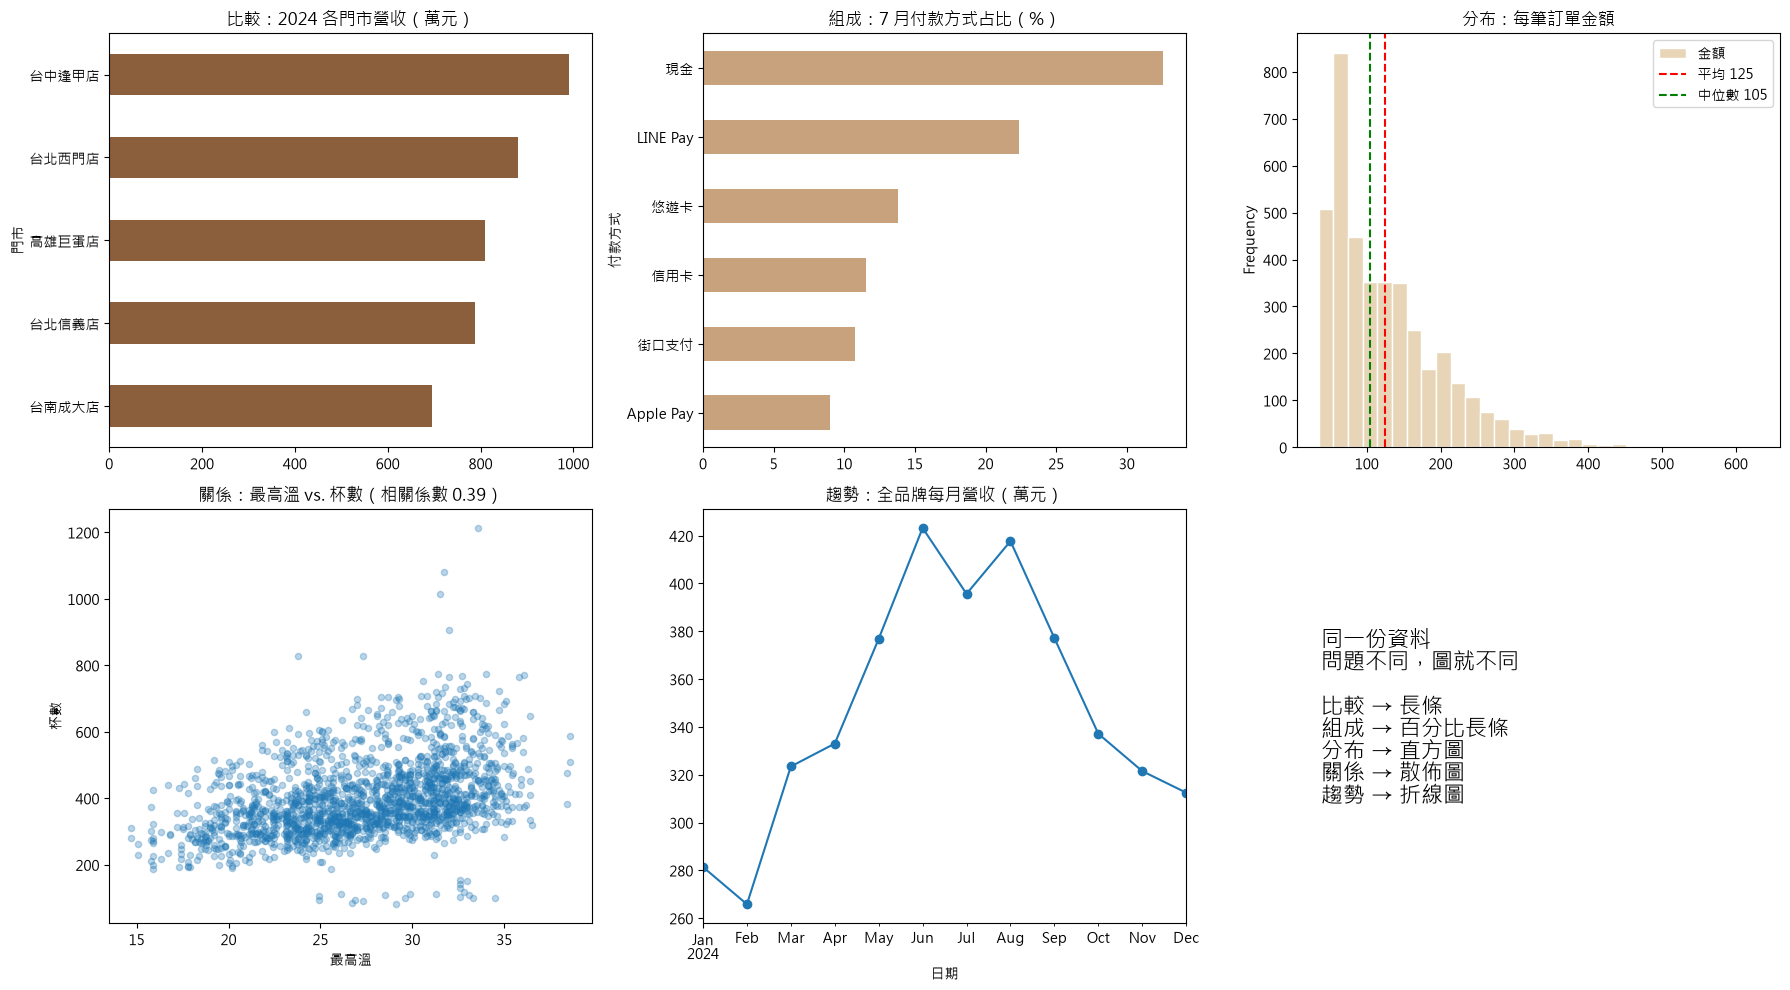

In [6]:
import os
import matplotlib.pyplot as plt
os.makedirs('給AI的圖表', exist_ok=True)
per_order = orders.groupby(['訂單編號', '門市', '付款方式'], as_index=False)['金額'].sum()   # 每筆訂單的總金額

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 比較：各店全年營收（排序長條圖）
(daily.groupby('門市')['營收'].sum().sort_values() / 10000).plot.barh(ax=axes[0, 0], color='#8B5E3C')
axes[0, 0].set_title('比較：2024 各門市營收（萬元）')

# 組成：付款方式占比（排序的百分比長條圖）
pay = per_order['付款方式'].value_counts(normalize=True).sort_values() * 100
pay.plot.barh(ax=axes[0, 1], color='#C8A27C')
axes[0, 1].set_title('組成：7 月付款方式占比（%）')

# 分布：每筆訂單金額（直方圖 + 平均與中位數）
per_order['金額'].plot.hist(ax=axes[0, 2], bins=30, color='#E8D5B7', edgecolor='white')
axes[0, 2].axvline(per_order['金額'].mean(), color='red', linestyle='--', label=f"平均 {per_order['金額'].mean():.0f}")
axes[0, 2].axvline(per_order['金額'].median(), color='green', linestyle='--', label=f"中位數 {per_order['金額'].median():.0f}")
axes[0, 2].legend()
axes[0, 2].set_title('分布：每筆訂單金額')

# 關係：最高溫 vs. 杯數（散佈圖）
daily.plot.scatter(x='最高溫', y='杯數', ax=axes[1, 0], alpha=0.3)
axes[1, 0].set_title(f"關係：最高溫 vs. 杯數（相關係數 {daily['最高溫'].corr(daily['杯數']):.2f}）")

# 趨勢：全品牌每月營收（折線圖）
(daily.set_index('日期')['營收'].resample('ME').sum() / 10000).plot(ax=axes[1, 1], marker='o')
axes[1, 1].set_title('趨勢：全品牌每月營收（萬元）')

axes[1, 2].axis('off')
axes[1, 2].text(0.05, 0.5, '同一份資料\n問題不同，圖就不同\n\n比較 → 長條\n組成 → 百分比長條\n分布 → 直方圖\n關係 → 散佈圖\n趨勢 → 折線圖',
                fontsize=16, va='center')
plt.tight_layout()
plt.savefig('給AI的圖表/五類問題五張圖.png', dpi=150, bbox_inches='tight')
plt.show()

> 💡 **看懂結果**：逢甲店營收最高；現金仍是最多人用的付款方式（約三成）；訂單金額的「平均」被少數大單拉高，**中位數**更能代表一般客人；氣溫和杯數呈正相關（約 0.39，因為不同門市的規模混在一起，相關程度被稀釋）；營收夏天最高，7 月因凱米颱風而低於 6 月與 8 月。

## 4. 錯誤示範 vs. 正確示範

同樣的數字，畫錯了就會誤導人。下面四組請先自己判斷哪裡有問題，再把圖交給 AI 問問看。

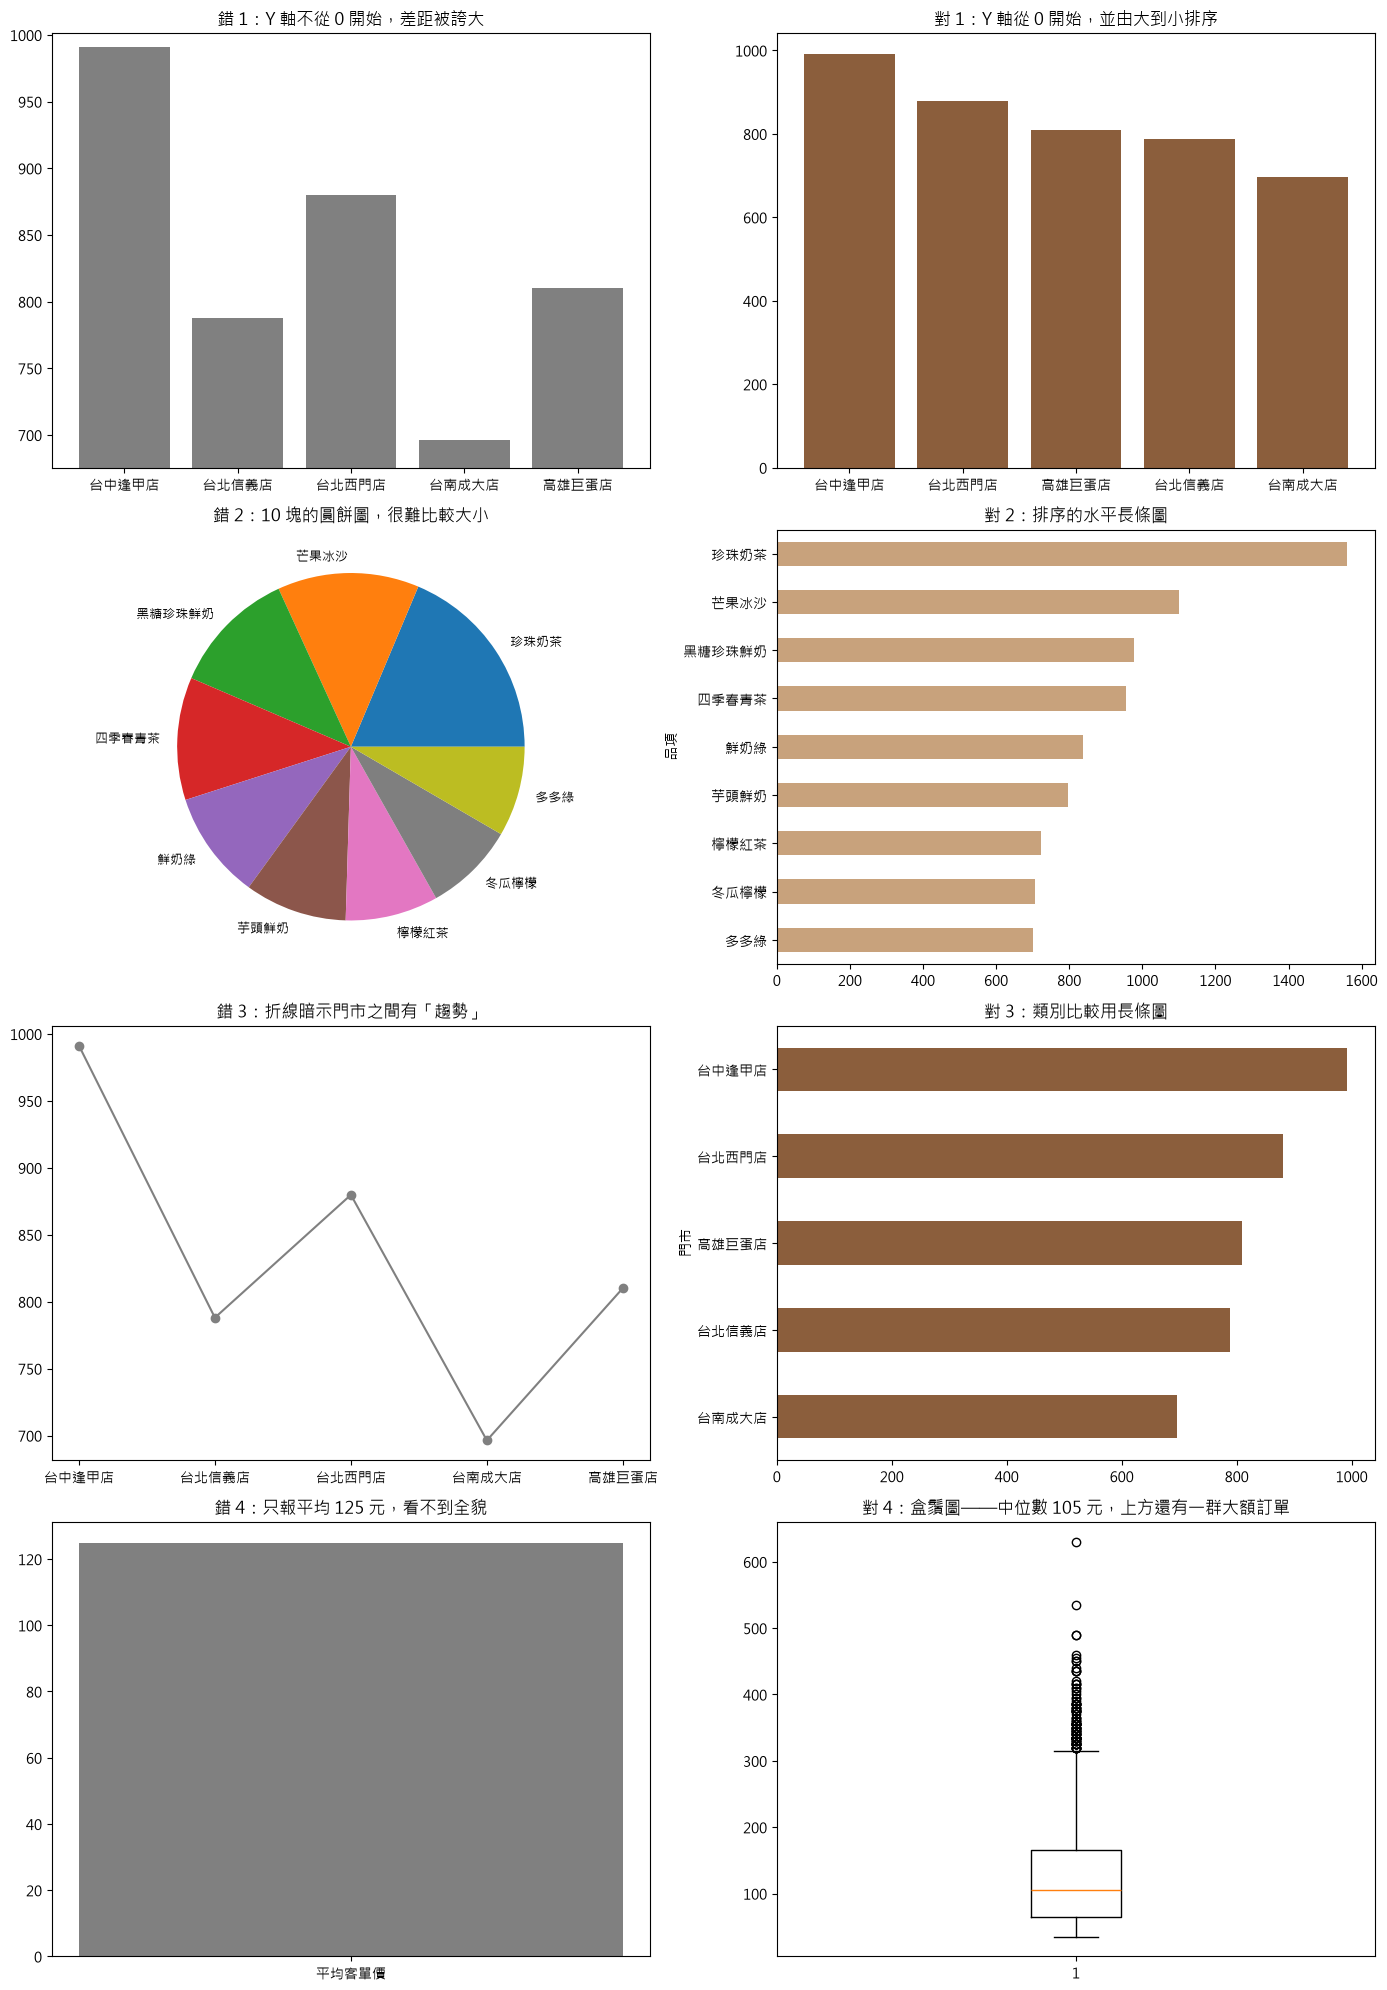

In [7]:
store_rev = daily.groupby('門市')['營收'].sum() / 10000
items = orders.groupby('品項')['數量'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(4, 2, figsize=(14, 20))

# ① Y 軸被截斷：差距看起來被誇大好幾倍
axes[0, 0].bar(store_rev.index, store_rev.values, color='gray')
axes[0, 0].set_ylim(store_rev.min() * 0.97, store_rev.max() * 1.01)
axes[0, 0].set_title('錯 1：Y 軸不從 0 開始，差距被誇大')
axes[0, 1].bar(store_rev.sort_values(ascending=False).index, store_rev.sort_values(ascending=False).values, color='#8B5E3C')
axes[0, 1].set_title('對 1：Y 軸從 0 開始，並由大到小排序')

# ② 太多塊的圓餅圖
axes[1, 0].pie(items.values, labels=items.index, textprops={'fontsize': 9})
axes[1, 0].set_title('錯 2：10 塊的圓餅圖，很難比較大小')
items.sort_values().plot.barh(ax=axes[1, 1], color='#C8A27C')
axes[1, 1].set_title('對 2：排序的水平長條圖')

# ③ 用折線連接「類別」：門市之間沒有先後順序
axes[2, 0].plot(store_rev.index, store_rev.values, marker='o', color='gray')
axes[2, 0].set_title('錯 3：折線暗示門市之間有「趨勢」')
store_rev.sort_values().plot.barh(ax=axes[2, 1], color='#8B5E3C')
axes[2, 1].set_title('對 3：類別比較用長條圖')

# ④ 只看平均：被少數大單誤導
po = per_order['金額']
axes[3, 0].bar(['平均客單價'], [po.mean()], color='gray', width=0.4)
axes[3, 0].set_title(f'錯 4：只報平均 {po.mean():.0f} 元，看不到全貌')
axes[3, 1].boxplot(po)
axes[3, 1].set_title(f'對 4：盒鬚圖——中位數 {po.median():.0f} 元，上方還有一群大額訂單')

plt.tight_layout()
plt.savefig('給AI的圖表/錯誤與正確示範.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. 把圖表交給 AI：解讀、診斷、改良

**怎麼給？** 對圖表按右鍵 →「複製圖片」，貼到 ChatGPT、Claude 或 Gemini 的對話框；或下載 `給AI的圖表/` 資料夾中的圖片後上傳。

| 用途 | 提示詞範本 |
| --- | --- |
| 🔎 **解讀** | 「這是手搖飲店 2024 年的五張分析圖（附圖）。請用白話列出 3 個最重要的發現，並說明是從哪張圖看出來的，最後給老闆 1 個具體建議。」 |
| 🩺 **診斷** | 「請用資料視覺化的專業標準檢查這張圖：有沒有誤導、難讀、或缺少的元素（標題、單位、排序、Y 軸起點）？請條列並說明怎麼改。」 |
| 🛠️ **改良** | 「請提供改良後的 matplotlib 程式碼，使用繁體中文標題與座標軸名稱。我的資料欄位是：（貼上欄位名稱）。」 |
| 🎯 **選圖** | 「我想讓主管一眼看出『哪一家店營收最高』，這張圓餅圖適合嗎？如果不適合，請推薦更好的圖表並說明理由。」 |

> **AI 回覆範例（示意）**——把「錯 1」那張圖交給 AI 診斷時，好的 AI 回答應該包含：
> - 「Y 軸從約 675 萬開始，而不是從 0 開始，讓台南成大店看起來只有台中逢甲店的一小截；實際上兩者只差約 42%（696 萬 vs. 991 萬）。」
> - 「長條沒有排序，讀者要自己找最高的門市。建議由大到小排序，並在長條上標示數值。」
> - 「標題沒有說明單位（萬元）與期間（2024 年）。」

## 6. 驗證 AI：用 pandas 核對每一個數字

AI 看圖時會「目測」，常常把數字讀錯，甚至把兩根長條看反。**AI 說的每個數字，都要用程式核對；AI 給的建議，要用你的商業常識判斷。**

In [8]:
print('▶ 各門市營收（萬元）：\n', store_rev.sort_values(ascending=False).round(0))
print('\n▶ 最高與最低門市差距：', f"{(store_rev.max() / store_rev.min() - 1) * 100:.0f}%")
print('\n▶ 訂單金額：平均', round(po.mean()), '／中位數', po.median(), '／最大', po.max())
print('\n▶ 付款方式占比 %：\n', pay.sort_values(ascending=False).round(1))

▶ 各門市營收（萬元）：
 門市
台中逢甲店    991.0
台北西門店    880.0
高雄巨蛋店    810.0
台北信義店    788.0
台南成大店    696.0
Name: 營收, dtype: float64

▶ 最高與最低門市差距： 42%

▶ 訂單金額：平均 125 ／中位數 105.0 ／最大 630

▶ 付款方式占比 %：
 付款方式
現金           32.6
LINE Pay     22.4
悠遊卡          13.8
信用卡          11.6
街口支付         10.7
Apple Pay     9.0
Name: proportion, dtype: float64


## 7. 畫完圖的檢查清單

- [ ] 我先判斷了每一欄的型態，沒有把識別碼拿去加總或平均。
- [ ] 我能說出這張圖在回答哪一類問題（比較、組成、分布、關係、趨勢）。
- [ ] 標題說得出重點，座標軸有名稱與單位。
- [ ] 長條圖的 Y 軸從 0 開始，類別有排序。
- [ ] 比較不同大小的群體時，用的是「比例」而不是「次數」。
- [ ] 我把圖交給 AI 解讀與診斷過，並**用 pandas 核對了 AI 說的數字**。

---

## ✍️ 練習題

1. 「哪個時段最忙？」屬於哪一類問題？用 `orders` 畫出來，並把圖交給 AI 解讀。
2. 「會員和非會員的客單價有差嗎？」該用什麼圖？畫出來後，請 AI 診斷你的圖。
3. 打開學生素材的「陌生資料挑戰」，用空氣品質資料走一次完整流程。

## 🔑 參考解答（先自己試試看！）

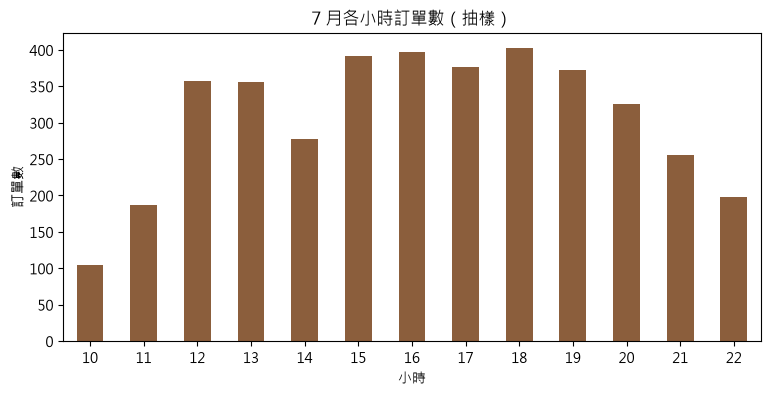

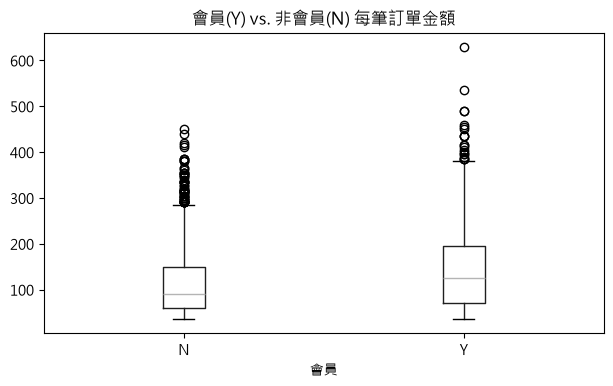

會員
N     90.0
Y    125.0
Name: 金額, dtype: float64


In [9]:
# 練習 1：比較（或趨勢）——各小時訂單數，用長條圖（小時有順序，依小時排列）
by_hour = orders.groupby(orders['訂單時間'].dt.hour)['訂單編號'].nunique()
ax = by_hour.plot.bar(color='#8B5E3C', rot=0, title='7 月各小時訂單數（抽樣）', figsize=(9, 4))
ax.set_xlabel('小時'); ax.set_ylabel('訂單數')
plt.savefig('給AI的圖表/各小時訂單數.png', dpi=150, bbox_inches='tight')
plt.show()

# 練習 2：比較 + 分布——會員 vs. 非會員的訂單金額，用盒鬚圖
member = orders.groupby(['訂單編號', '會員'], as_index=False)['金額'].sum()
member.boxplot(column='金額', by='會員', grid=False, figsize=(7, 4))
plt.suptitle(''); plt.title('會員(Y) vs. 非會員(N) 每筆訂單金額')
plt.show()
print(member.groupby('會員')['金額'].median())